# UTS Machine Learning - Jalur B (Regresi)
## Prediksi Harga Sewa Per Malam Properti Airbnb di Bali

| | |
|---|---|
| **NIM** | 2301010304 |
| **Nama** | KADEK AGUS SAPUTRA |
| **Kelas** | XX |
| **Jalur** | B - Regresi |
| **Random state (SEED)** | 304 (3 digit terakhir NIM) |

Alur notebook mengikuti 6 tahap CRISP-DM. Setiap tahap ditutup sel **Keputusan saya** yang berisi apa yang saya lakukan dan alasannya.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 304   # 3 digit terakhir NIM 2301010304, dipakai di SEMUA proses acak
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

# Cari file data otomatis (laptop: ../data/ | Colab: upload CSV ke panel Files)
import os
CANDIDATES = ["../data/listings_bali_201804.csv", "data/listings_bali_201804.csv", "listings_bali_201804.csv"]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
assert DATA_PATH, "listings_bali_201804.csv tidak ditemukan: taruh di folder data/ atau upload ke folder yang sama dengan notebook"
REPORTS = "../reports" if os.path.isdir("../reports") else "reports"
os.makedirs(REPORTS, exist_ok=True)

# Tahap 1 - Pemahaman Masalah dan Data

**Tujuan analisis.** Membangun model regresi yang memprediksi **harga sewa per malam (USD)** sebuah properti Airbnb di Bali dari karakteristiknya (jumlah kamar mandi, kapasitas tamu, jenis kamar, kawasan, dan lain-lain).

**Pengguna hasil.** Calon *host* yang ingin menentukan harga wajar untuk propertinya, dan wisatawan yang ingin menilai apakah harga sebuah listing masuk akal.

**Keputusan yang terbantu.** Host bisa menetapkan harga awal berbasis data, bukan tebakan. Wisatawan bisa melihat listing yang jauh lebih mahal atau murah dari harga prediksi.

**Sumber data.** *Bali Airbnb April 2018* oleh David Moriano, hasil scraping airbnb.com pada April 2018.
Link: https://github.com/daben/m2851-prac1 (diakses 25 November 2026).
Lisensi: **CC BY-NC 4.0** (boleh dipakai non-komersial dengan atribusi). Data bukan daftar lengkap seluruh listing Bali, menurut penulisnya sendiri.

**Anonimisasi.** Kolom identitas host (`user_id`, `user_name`) dan judul listing (`name`) sudah dibuang dari salinan data di repositori ini sesuai prinsip UU PDP.

**Deskripsi kolom (yang dipakai atau relevan):**

| Kolom | Arti | Tipe | Satuan |
|---|---|---|---|
| `price_rate` | Harga sewa per malam (**target**) | numerik | USD |
| `bedrooms` | Jumlah kamar tidur | numerik | buah |
| `bathrooms` | Jumlah kamar mandi | numerik | buah |
| `beds` | Jumlah tempat tidur | numerik | buah |
| `person_capacity` | Kapasitas tamu | numerik | orang |
| `reviews_count` | Jumlah ulasan | numerik | buah |
| `star_rating` | Rating bintang dari tamu (1-5) | numerik | bintang |
| `room_type` | Jenis kamar (`entire_home`, `private_room`, `shared_room`) | kategori | - |
| `neighborhood` | Kawasan di Bali (21 kawasan) | kategori | - |
| `city`, `latitude`, `longitude` | Lokasi | kategori / numerik | - |
| `superhost`, `verified`, `refundable`, `new_listing`, `business_travel_ready` | Status listing / host | boolean | - |
| `host_languages`, `scrim_color`, `section_offset`, `tier_id`, `property_type`, `*_price_factor`, `price_rate_type` | Metadata scraping dan diskon | campuran | - |

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Ukuran data:", df_raw.shape)
print("Jumlah baris duplikat:", df_raw.duplicated().sum())
print("Jenis price_rate_type:", df_raw["price_rate_type"].unique())
df_raw.head()

Ukuran data: (12228, 26)
Jumlah baris duplikat: 0
Jenis price_rate_type: <StringArray>
['nightly']
Length: 1, dtype: str


,_id,bathrooms,bedrooms,beds,business_travel_ready,city,host_languages,latitude,longitude,monthly_price_factor,neighborhood,new_listing,person_capacity,price_rate,price_rate_type,property_type,refundable,reviews_count,room_type,scrim_color,section_offset,star_rating,superhost,tier_id,verified,weekly_price_factor
0,3692901,1.0,1.0,1.0,False,Amed,NaN,-8.335871,115.649070,1.0,Amed,False,2,14,nightly,3.0,False,107,private_room,#1B2212,1,4.0,False,0,False,1.00
1,16849082,1.0,1.0,1.0,False,Karangasem Regency,"en,id",-8.336109,115.650263,0.9,Amed,False,2,13,nightly,40.0,False,45,private_room,#272822,1,4.5,False,0,False,0.93
2,7058723,1.0,1.0,1.0,False,Karangasem Regency,NaN,-8.334680,115.646764,1.0,Amed,False,2,10,nightly,3.0,False,33,private_room,#352A24,1,4.5,False,0,False,1.00
3,7058890,1.0,1.0,1.0,False,Karangasem Regency,NaN,-8.334861,115.646965,1.0,Amed,False,2,10,nightly,3.0,False,71,private_room,#27262C,1,4.5,False,0,False,1.00
4,16978040,2.0,1.0,6.0,False,Abang,fr,-8.338911,115.657967,1.0,Amed,False,1,10,nightly,9.0,False,2,shared_room,#150E06,1,NaN,True,0,False,1.00


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 12228 entries, 0 to 12227
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   _id                    12228 non-null  int64  
 1   bathrooms              12212 non-null  float64
 2   bedrooms               12223 non-null  float64
 3   beds                   12218 non-null  float64
 4   business_travel_ready  12228 non-null  bool   
 5   city                   12052 non-null  str    
 6   host_languages         7951 non-null   str    
 7   latitude               12228 non-null  float64
 8   longitude              12228 non-null  float64
 9   monthly_price_factor   12228 non-null  float64
 10  neighborhood           12228 non-null  str    
 11  new_listing            12228 non-null  bool   
 12  person_capacity        12228 non-null  int64  
 13  price_rate             12228 non-null  int64  
 14  price_rate_type        12228 non-null  str    
 15  property_type

### Keputusan saya (Tahap 1)

- Dataset berisi **12.228 baris dan 26 kolom** (syarat minimal: 200 baris dan 4 fitur), jadi memenuhi syarat.
- Target adalah `price_rate` (numerik, USD per malam), sehingga masalahnya adalah **regresi** dan jalur B tepat.
- Semua baris bertipe harga `nightly`, jadi harga antar baris sebanding tanpa perlu konversi.
- Kolom yang tidak berhubungan dengan harga (id, warna *scrim*, nomor halaman scraping) tidak akan dipakai sebagai fitur.

# Tahap 2 - Eksplorasi dan Visualisasi

Eksplorasi di tahap ini bersifat **deskriptif** (melihat pola), belum ada transformasi yang dipelajari dari data. Semua keputusan yang menghitung statistik (batas outlier, nilai imputasi) baru dihitung di Tahap 3 dari **data latih saja**.

In [4]:
eda = df_raw[df_raw["price_rate"] > 0].copy()   # 9 baris berharga 0 tidak valid
print("Baris dengan harga <= 0 (dibuang):", (df_raw["price_rate"] <= 0).sum())
print(eda["price_rate"].describe().round(2))
print("Persentase harga <= 1000 USD:", round((eda["price_rate"] <= 1000).mean() * 100, 1), "%")

Baris dengan harga <= 0 (dibuang): 9
count     12219.00
mean        276.77
std        3276.04
min           4.00
25%          66.00
50%         159.00
75%         309.00
max      360500.00
Name: price_rate, dtype: float64
Persentase harga <= 1000 USD: 97.8 %


**Grafik 1 - Distribusi harga (target).** Dipotong di 1.000 USD agar bentuknya terlihat, karena maksimum data mencapai 360.500 USD.

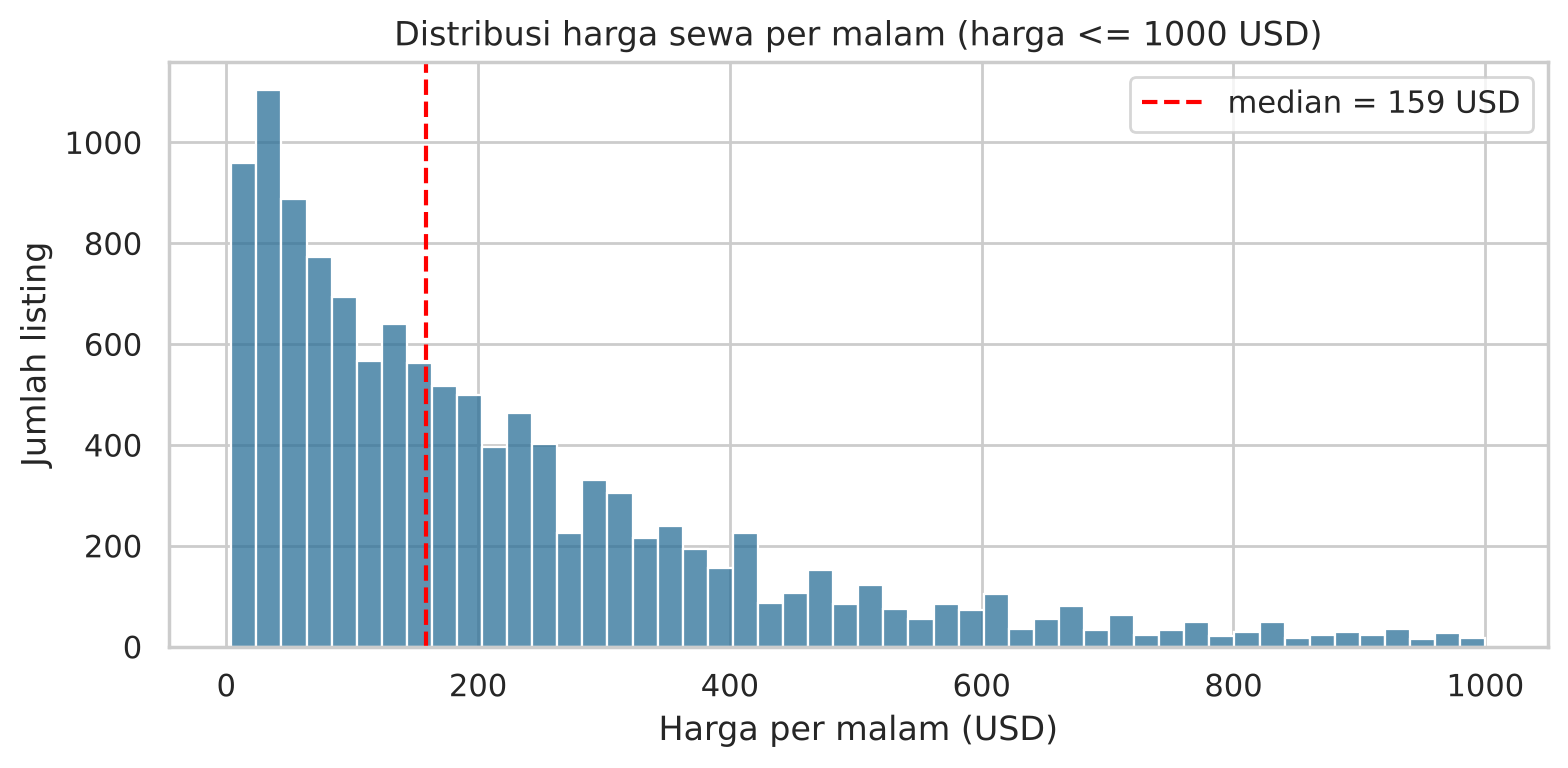

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(eda.loc[eda["price_rate"] <= 1000, "price_rate"], bins=50, ax=ax, color="#2a6f97")
ax.axvline(eda["price_rate"].median(), color="red", ls="--", label=f"median = {eda['price_rate'].median():.0f} USD")
ax.set_xlabel("Harga per malam (USD)"); ax.set_ylabel("Jumlah listing")
ax.set_title("Distribusi harga sewa per malam (harga <= 1000 USD)")
ax.legend(); plt.tight_layout()
plt.savefig(f"{REPORTS}/grafik1_distribusi_harga.png", dpi=150); plt.show()

**Interpretasi.** Distribusi harga miring ke kanan: sebagian besar listing murah, sedikit sekali yang sangat mahal. Median harga 159 USD sedangkan rata-rata 276,77 USD, ditarik naik oleh harga ekstrem (maksimum 360.500 USD). Jadi **median lebih mewakili harga tipikal** dan perlu penanganan outlier.

**Grafik 2 - Harga menurut jenis kamar dan kawasan.**

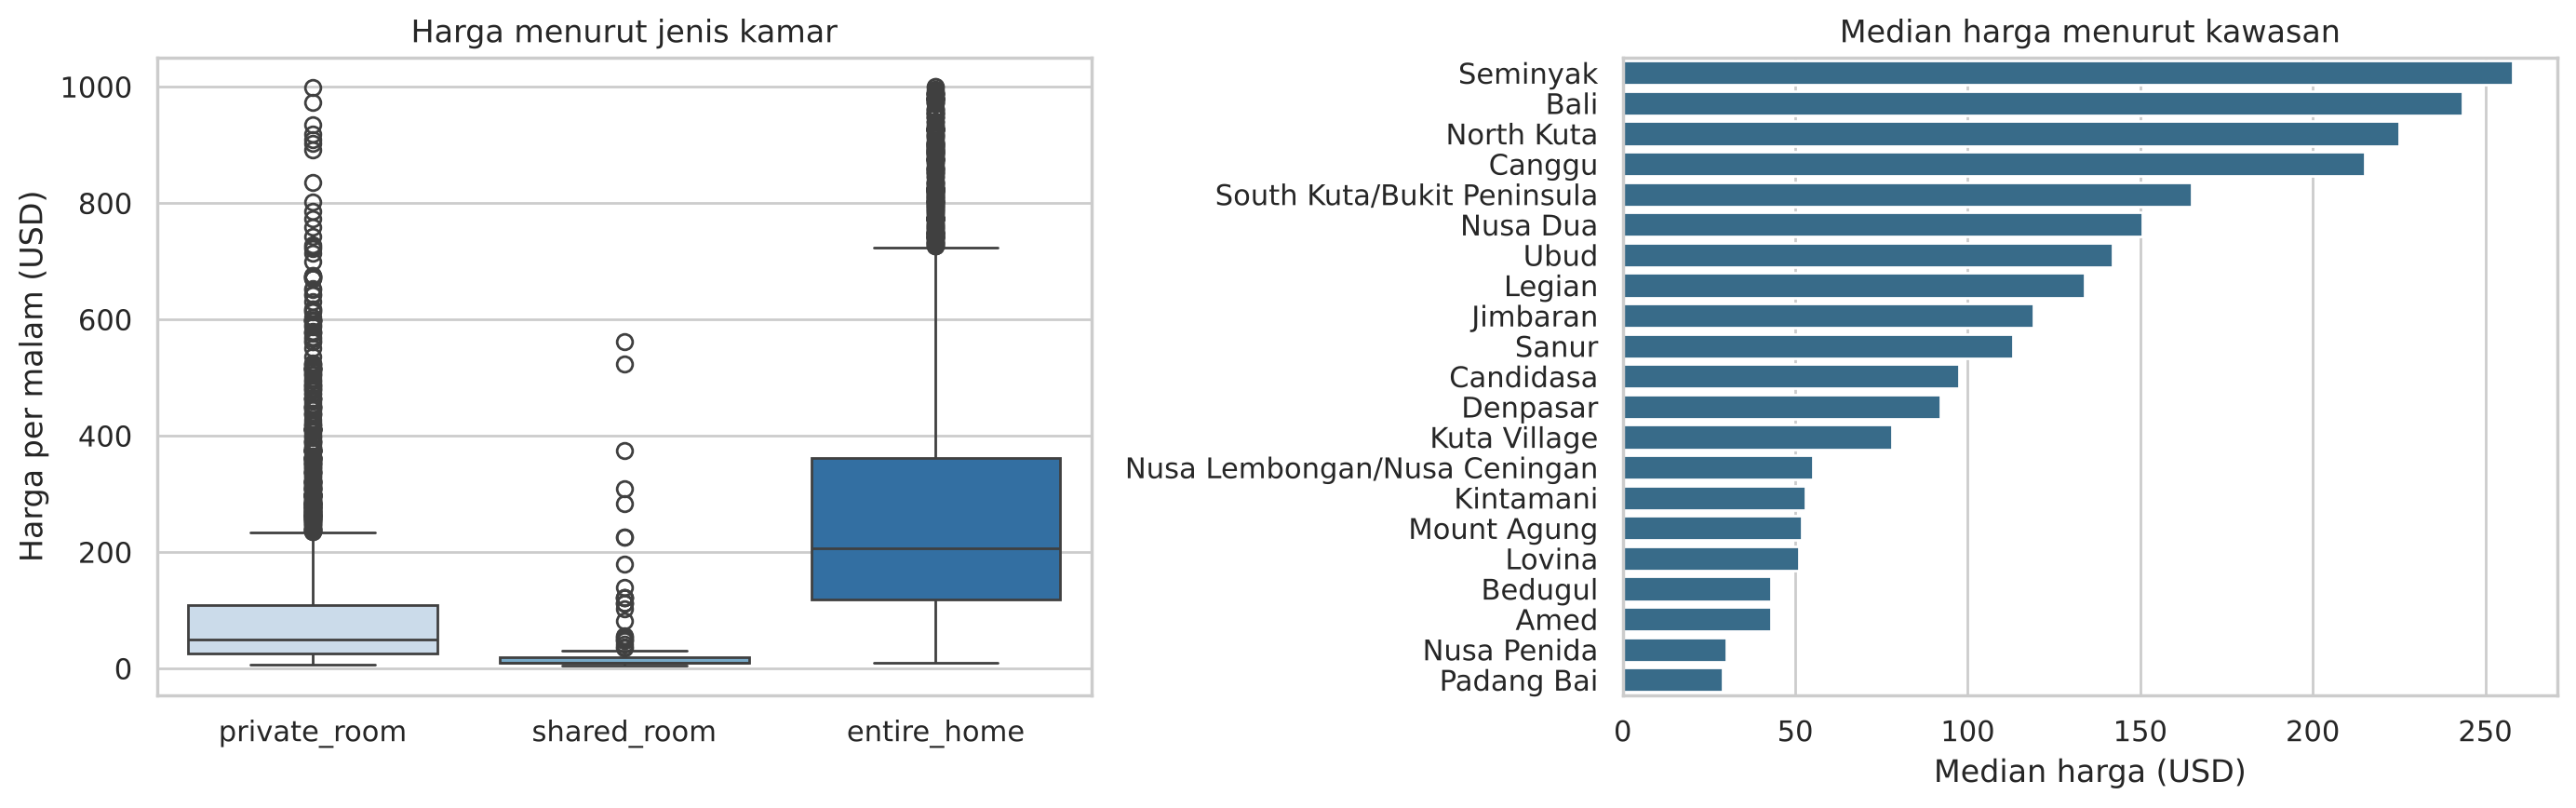

              count  median
room_type                  
entire_home    8405   206.0
private_room   3375    49.0
shared_room     167    10.0


In [6]:
e = eda[eda["price_rate"] <= 1000]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=e, x="room_type", y="price_rate", ax=axes[0], palette="Blues")
axes[0].set_title("Harga menurut jenis kamar"); axes[0].set_xlabel(""); axes[0].set_ylabel("Harga per malam (USD)")

order = e.groupby("neighborhood")["price_rate"].median().sort_values(ascending=False).index
sns.barplot(data=e, x="price_rate", y="neighborhood", order=order, estimator=np.median, errorbar=None, ax=axes[1], color="#2a6f97")
axes[1].set_title("Median harga menurut kawasan"); axes[1].set_xlabel("Median harga (USD)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.savefig(f"{REPORTS}/grafik2_jenis_kamar_kawasan.png", dpi=150); plt.show()
print(e.groupby("room_type")["price_rate"].agg(["count", "median"]))

**Interpretasi.** Jenis kamar sangat menentukan harga: median `entire_home` 206 USD, `private_room` 49 USD, dan `shared_room` hanya 10 USD. Kawasan juga berpengaruh: Seminyak punya median harga tertinggi (258 USD), disusul kawasan "Bali" (244 USD) dan North Kuta (225 USD), sedangkan Padang Bai (29 USD) dan Nusa Penida (30 USD) paling murah. Maka `room_type` dan `neighborhood` layak dijadikan fitur kategori.

**Grafik 3 - Hubungan fitur numerik dengan harga.**

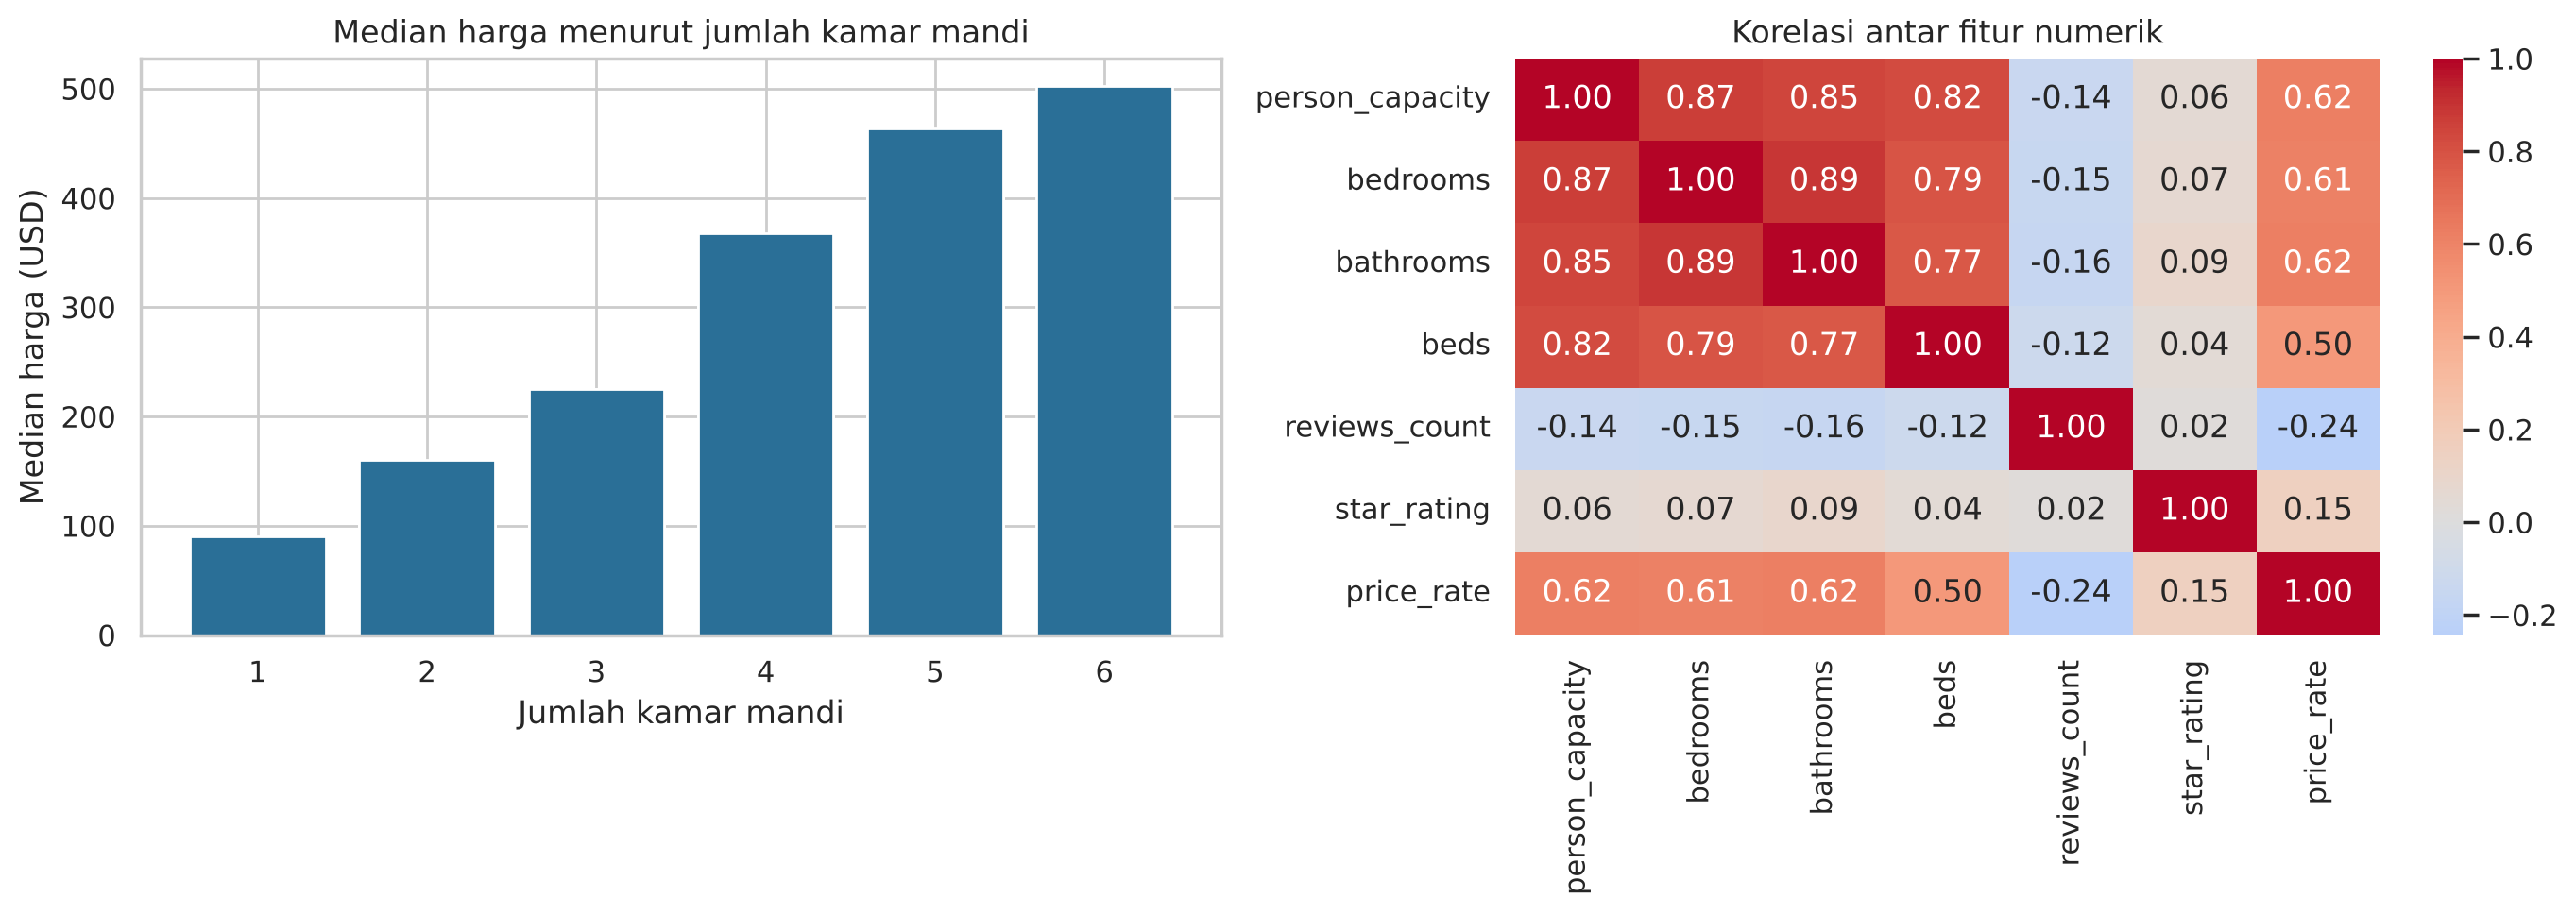

bathrooms
1.0     52.0
1.5     90.0
2.0    143.0
2.5    160.5
3.0    225.0
3.5    225.0
4.0    339.5
4.5    368.0
5.0    412.0
5.5    464.0
6.0    502.5
Name: price_rate, dtype: float64


In [7]:
num_cols = ["person_capacity", "bedrooms", "bathrooms", "beds", "reviews_count", "star_rating", "price_rate"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
med = e[e["bathrooms"].between(1, 6)].groupby("bathrooms")["price_rate"].median()
axes[0].bar(med.index.astype(int).astype(str), med.values, color="#2a6f97")
axes[0].set_title("Median harga menurut jumlah kamar mandi"); axes[0].set_xlabel("Jumlah kamar mandi"); axes[0].set_ylabel("Median harga (USD)")

sns.heatmap(e[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Korelasi antar fitur numerik")
plt.tight_layout(); plt.savefig(f"{REPORTS}/grafik3_korelasi.png", dpi=150); plt.show()
print(med)

**Interpretasi.** Median harga naik tegas seiring jumlah kamar mandi: 52 USD (1 kamar mandi), 143 USD (2), 225 USD (3), sampai 502,5 USD (6). Fitur dengan korelasi tertinggi terhadap harga adalah `person_capacity` (0,62), `bathrooms` (0,62), dan `bedrooms` (0,61). Perhatikan juga bahwa **fitur-fitur ini saling berkorelasi sangat kuat** (misalnya `bedrooms` dengan `bathrooms` 0,89), yang akan mempengaruhi cara membaca koefisien regresi berganda nanti. `reviews_count` berkorelasi negatif lemah (-0,24), kemungkinan karena listing murah lebih sering disewa dan diulas.

### Keputusan saya (Tahap 2)

- Harga sangat miring ke kanan dengan nilai ekstrem, sehingga outlier harga perlu ditangani (Tahap 3).
- `room_type` dan `neighborhood` dipakai sebagai fitur kategori karena median harganya berbeda jauh antar kelompok.
- Fitur numerik yang dipakai: `person_capacity`, `bedrooms`, `bathrooms`, `beds`, `reviews_count`, `star_rating`.
- Fitur untuk **regresi sederhana** akan dipilih dari korelasi tertinggi, dihitung dari data latih saja.

# Tahap 3 - Pra-pemrosesan

Urutan kerja agar **bebas kebocoran data (data leakage)**:
1. Buang baris yang jelas tidak valid (harga 0). Ini aturan tetap, bukan statistik yang dipelajari dari data.
2. **Bagi data latih dan uji dulu** (80/20, `random_state=SEED`).
3. Hitung batas outlier IQR dari **data latih saja**.
4. Imputasi dan encoding dilakukan di dalam `Pipeline`, sehingga di-*fit* hanya pada data latih (dan pada tiap fold saat cross-validation).

In [8]:
# 1. Buang harga tidak valid
df = df_raw[df_raw["price_rate"] > 0].copy()
print("Setelah buang harga 0:", df.shape)

# 2. Split dulu
train_all, test_all = train_test_split(df, test_size=0.2, random_state=SEED)
print("Latih:", train_all.shape, "| Uji:", test_all.shape)

Setelah buang harga 0: (12219, 26)
Latih: (9775, 26) | Uji: (2444, 26)


**Pengecekan kualitas data pada data latih.**

In [9]:
cek_cols = ["price_rate", "bedrooms", "bathrooms", "beds", "person_capacity", "reviews_count", "star_rating", "room_type", "neighborhood"]
print("Missing value (data latih):")
print(train_all[cek_cols].isna().sum()[lambda s: s > 0])
print()
print("Persentase star_rating kosong:", round(train_all["star_rating"].isna().mean() * 100, 1), "%")
print()
print("Nilai unik room_type  :", sorted(train_all["room_type"].unique()))
print("Jumlah neighborhood   :", train_all["neighborhood"].nunique())
print("Ejaan neighborhood ada spasi/huruf besar-kecil berbeda?",
      train_all["neighborhood"].nunique() != train_all["neighborhood"].str.strip().str.lower().nunique())
print("Jumlah city unik (mentah):", df["city"].nunique(), "-> terlalu berantakan, tidak dipakai")

Missing value (data latih):
bedrooms          4
bathrooms        12
beds              8
star_rating    5295
dtype: int64

Persentase star_rating kosong: 54.2 %

Nilai unik room_type  : ['entire_home', 'private_room', 'shared_room']
Jumlah neighborhood   : 21
Ejaan neighborhood ada spasi/huruf besar-kecil berbeda? False
Jumlah city unik (mentah): 538 -> terlalu berantakan, tidak dipakai


**Outlier harga dengan metode IQR** (batas dihitung dari data latih saja).

In [10]:
Q1, Q3 = train_all["price_rate"].quantile([0.25, 0.75])
IQR = Q3 - Q1
batas_atas = Q3 + 1.5 * IQR
print(f"Q1 = {Q1:.0f}, Q3 = {Q3:.0f}, IQR = {IQR:.0f}, batas atas = {batas_atas:.0f} USD")

train = train_all[train_all["price_rate"] <= batas_atas].copy()
test  = test_all[test_all["price_rate"] <= batas_atas].copy()
print(f"Data latih: {len(train_all)} -> {len(train)}  (dibuang {len(train_all)-len(train)})")
print(f"Data uji  : {len(test_all)} -> {len(test)}  (dibuang {len(test_all)-len(test)})")
print("Skewness harga latih setelah outlier dibuang:", round(train['price_rate'].skew(), 2))

Q1 = 67, Q3 = 309, IQR = 242, batas atas = 672 USD
Data latih: 9775 -> 9147  (dibuang 628)
Data uji  : 2444 -> 2290  (dibuang 154)
Skewness harga latih setelah outlier dibuang: 1.04


**Fitur dan pipeline.**

In [11]:
num_features = ["person_capacity", "bedrooms", "bathrooms", "beds", "reviews_count", "star_rating"]
cat_features = ["room_type", "neighborhood"]
target = "price_rate"

X_train, y_train = train[num_features + cat_features], train[target]
X_test,  y_test  = test[num_features + cat_features],  test[target]

# Fitur untuk regresi sederhana = korelasi (absolut) tertinggi dengan harga, dihitung dari DATA LATIH
korelasi = train[num_features + [target]].corr()[target].drop(target)
print(korelasi.round(3).sort_values(ascending=False))
fitur_sederhana = korelasi.abs().idxmax()
print("\nFitur regresi sederhana:", fitur_sederhana)

def buat_pipeline(model, num, cat):
    langkah = []
    if num:
        langkah.append(("num", SimpleImputer(strategy="median"), num))
    if cat:
        langkah.append(("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat))
    return Pipeline([("prep", ColumnTransformer(langkah)), ("model", model)])

bathrooms          0.602
person_capacity    0.597
bedrooms           0.582
beds               0.458
star_rating        0.148
reviews_count     -0.240
Name: price_rate, dtype: float64

Fitur regresi sederhana: bathrooms


### Keputusan saya (Tahap 3)

- **Harga 0 (9 baris) dibuang** karena listing tidak mungkin disewakan gratis, jelas data tidak valid.
- **Split 80/20 dilakukan sebelum** menghitung apa pun dari data, dengan `random_state=304`. Data uji tidak disentuh sampai Tahap 5.
- **Outlier harga:** batas atas IQR dihitung dari data latih (672 USD) lalu dipakai ke data latih dan uji. Ini menetapkan cakupan model: *harga wajar sampai 672 USD per malam*. Villa mewah di atas itu bukan target model ini. Konsekuensinya model tidak boleh dipakai untuk memprediksi listing super mewah.
- **Missing value:** `star_rating` kosong sekitar 54%, kemungkinan karena listing baru belum punya ulasan. Saya imputasi **median** (dihitung dari data latih di dalam Pipeline) dan **tidak membuang barisnya**, karena akan menghilangkan lebih dari separuh data. Kolom `bedrooms`, `bathrooms`, `beds` hanya kosong belasan baris, juga diimputasi median.
- **Kategori:** `room_type` dan `neighborhood` di-*one-hot encode* (`handle_unknown="ignore"` supaya aman bila ada kawasan langka di data uji). Ejaan `neighborhood` sudah konsisten (21 nilai). Kolom `city` dibuang karena memiliki 538 nilai dengan ejaan berantakan, dan informasinya sudah terwakili `neighborhood`.
- **Scaling tidak dipakai** karena regresi linear tidak sensitif pada skala, dan tanpa scaling koefisien tetap mudah dibaca dalam satuan asli (USD per unit).
- Kolom `_id`, `latitude`, `longitude`, `scrim_color`, `section_offset`, `tier_id`, `property_type`, `*_price_factor` tidak dipakai: bukan karakteristik properti yang bermakna atau sulit ditafsirkan.

# Tahap 4 - Pemodelan

Tiga model dibandingkan dengan **5-fold cross-validation pada data latih saja** (`KFold(shuffle=True, random_state=SEED)`):

1. **DummyRegressor** - baseline: selalu menebak rata-rata harga.
2. **Regresi linear sederhana** - 1 fitur terbaik.
3. **Regresi linear berganda** - banyak fitur (numerik + kategori).

Data uji **belum dipakai** di tahap ini.

In [12]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

model_cv = {
    "Dummy (rata-rata)":        (buat_pipeline(DummyRegressor(strategy="mean"), num_features, []), num_features),
    f"Sederhana ({fitur_sederhana})": (buat_pipeline(LinearRegression(), [fitur_sederhana], []), [fitur_sederhana]),
    "Berganda":                 (buat_pipeline(LinearRegression(), num_features, cat_features), num_features + cat_features),
}

baris, mae_fold = [], {}
for nama, (pipe, kolom) in model_cv.items():
    hasil = cross_validate(pipe, X_train[kolom], y_train, cv=cv,
                           scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
    mae_fold[nama] = -hasil["test_neg_mean_absolute_error"]
    baris.append({"Model": nama,
                  "MAE CV (USD)": -hasil["test_neg_mean_absolute_error"].mean(),
                  "RMSE CV (USD)": -hasil["test_neg_root_mean_squared_error"].mean(),
                  "R2 CV": hasil["test_r2"].mean(),
                  "Std MAE antar fold": (-hasil["test_neg_mean_absolute_error"]).std()})

tabel_cv = pd.DataFrame(baris).set_index("Model").round(3)
tabel_cv

,MAE CV (USD),RMSE CV (USD),R2 CV,Std MAE antar fold
Model,,,,
Dummy (rata-rata),125.094,155.488,-0.000,1.529
Sederhana (bathrooms),91.685,124.282,0.360,1.642
Berganda,80.087,107.924,0.518,1.704


MAE tiap fold:
        Dummy (rata-rata)  Sederhana (bathrooms)  Berganda
fold 1              122.8                   88.8      76.7
fold 2              126.2                   93.6      80.8
fold 3              126.7                   92.9      80.8
fold 4              126.0                   91.7      81.3
fold 5              123.8                   91.4      80.9


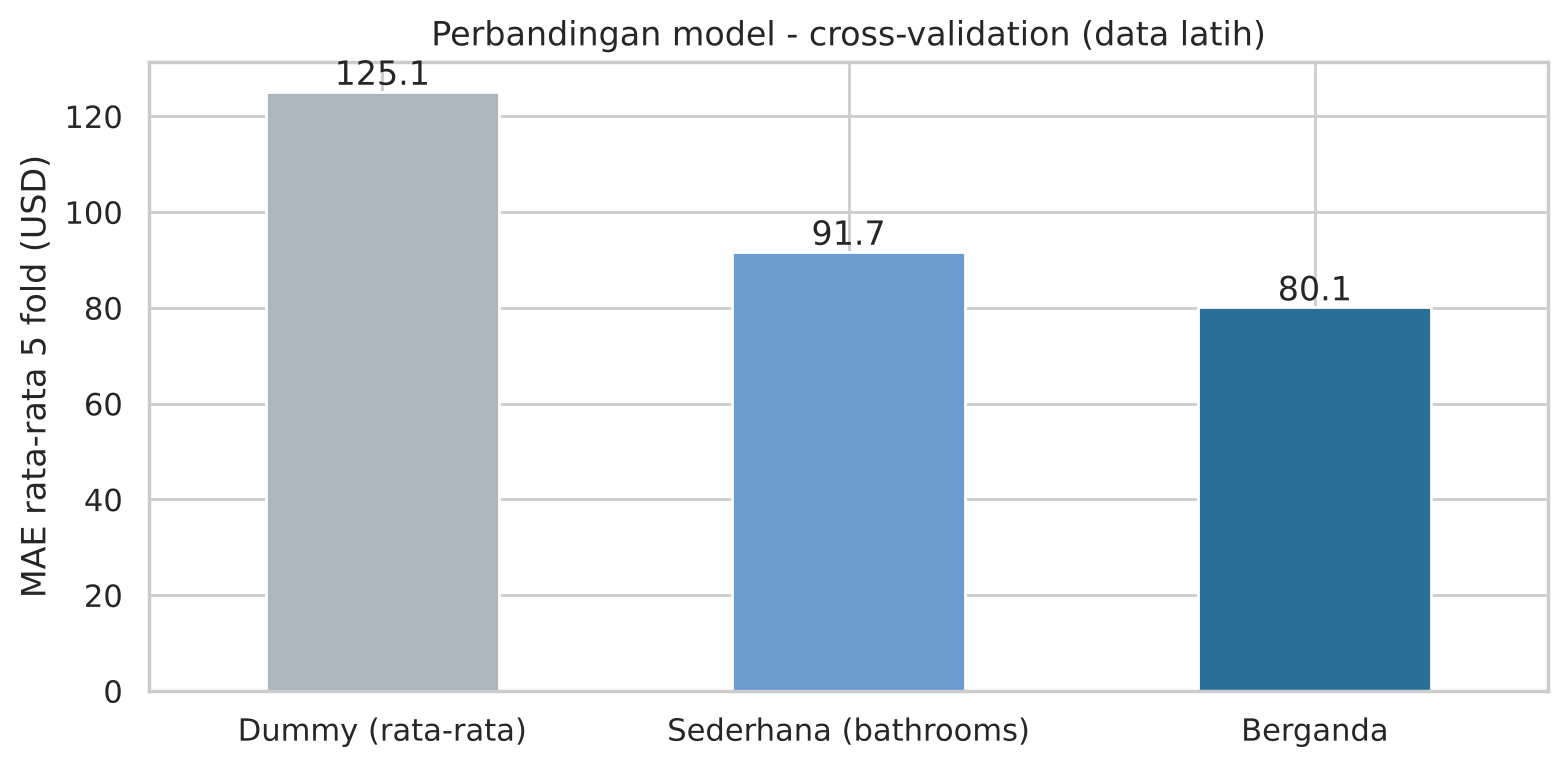

In [13]:
print("MAE tiap fold:")
print(pd.DataFrame(mae_fold, index=[f"fold {i}" for i in range(1, 6)]).round(1))

fig, ax = plt.subplots(figsize=(8, 4))
tabel_cv["MAE CV (USD)"].plot.bar(ax=ax, color=["#adb5bd", "#6c9bcf", "#2a6f97"], rot=0)
for i, v in enumerate(tabel_cv["MAE CV (USD)"]):
    ax.text(i, v + 1.5, f"{v:.1f}", ha="center")
ax.set_ylabel("MAE rata-rata 5 fold (USD)"); ax.set_xlabel("")
ax.set_title("Perbandingan model - cross-validation (data latih)")
plt.tight_layout(); plt.savefig(f"{REPORTS}/grafik4_cv_model.png", dpi=150); plt.show()

**Interpretasi.** Pada cross-validation 5 fold, DummyRegressor memiliki MAE 125,09 USD (R² 0,00, sesuai dugaan karena hanya menebak rata-rata). Regresi sederhana dengan `bathrooms` menurunkan MAE menjadi 91,68 USD (R² 0,36), dan regresi berganda menurunkannya lagi menjadi 80,09 USD (R² 0,52). Skor antar fold stabil (MAE regresi berganda 76,7 sampai 81,3 USD), jadi hasilnya tidak bergantung pada pembagian fold tertentu.

### Keputusan saya (Tahap 4)

- Regresi linear **tidak punya hyperparameter yang perlu di-tuning**, sehingga cross-validation dipakai untuk **membandingkan model**, bukan memilih parameter.
- Fitur regresi sederhana dipilih otomatis dari korelasi tertinggi pada data latih (`bathrooms`).
- **Regresi berganda dipilih** sebagai model utama karena MAE CV terendah (80,09 USD) dan jauh di bawah baseline (125,09 USD).

# Tahap 5 - Evaluasi dan Interpretasi

Sekarang **data uji dibuka satu kali saja**. Setiap model dilatih ulang dengan seluruh data latih, lalu dinilai pada data uji.

In [14]:
hasil_uji, pred_uji, model_final = [], {}, {}
for nama, (pipe, kolom) in model_cv.items():
    pipe.fit(X_train[kolom], y_train)
    p_te, p_tr = pipe.predict(X_test[kolom]), pipe.predict(X_train[kolom])
    pred_uji[nama], model_final[nama] = p_te, pipe
    hasil_uji.append({"Model": nama,
        "MAE uji": mean_absolute_error(y_test, p_te),
        "RMSE uji": np.sqrt(mean_squared_error(y_test, p_te)),
        "R2 uji": r2_score(y_test, p_te),
        "MAE latih": mean_absolute_error(y_train, p_tr),
        "R2 latih": r2_score(y_train, p_tr)})

tabel_uji = pd.DataFrame(hasil_uji).set_index("Model").round(3)
tabel_uji

,MAE uji,RMSE uji,R2 uji,MAE latih,R2 latih
Model,,,,,
Dummy (rata-rata),126.643,157.814,-0.001,125.085,0.000
Sederhana (bathrooms),91.358,130.322,0.317,91.654,0.362
Berganda,79.548,107.561,0.535,79.780,0.523


**Perhitungan manual MAE dan R2** dari prediksi regresi berganda, untuk memastikan paham rumusnya.

In [15]:
nama_terbaik = "Berganda"
y_asli = y_test.values
y_pred = pred_uji[nama_terbaik]

# MAE manual = rata-rata |asli - prediksi|
mae_manual = np.mean(np.abs(y_asli - y_pred))
# R2 manual = 1 - SS_residual / SS_total
ss_res = np.sum((y_asli - y_pred) ** 2)
ss_tot = np.sum((y_asli - y_asli.mean()) ** 2)
r2_manual = 1 - ss_res / ss_tot

print(f"MAE manual = {mae_manual:.3f}  | sklearn = {mean_absolute_error(y_asli, y_pred):.3f}")
print(f"R2  manual = {r2_manual:.3f}  | sklearn = {r2_score(y_asli, y_pred):.3f}")

print("\nContoh 5 listing pertama di data uji:")
contoh = pd.DataFrame({"harga_asli": y_asli[:5], "prediksi": y_pred[:5].round(1)})
contoh["selisih_mutlak"] = (contoh["harga_asli"] - contoh["prediksi"]).abs().round(1)
print(contoh)
print("MAE 5 contoh ini =", round(contoh["selisih_mutlak"].mean(), 2), "USD")

MAE manual = 79.548  | sklearn = 79.548
R2  manual = 0.535  | sklearn = 0.535

Contoh 5 listing pertama di data uji:
   harga_asli  prediksi  selisih_mutlak
0         262     210.6            51.4
1         172     168.6             3.4
2         330     300.7            29.3
3          43     151.1           108.1
4         227     196.1            30.9
MAE 5 contoh ini = 44.62 USD


**Grafik prediksi vs aktual dan residual** (regresi berganda).

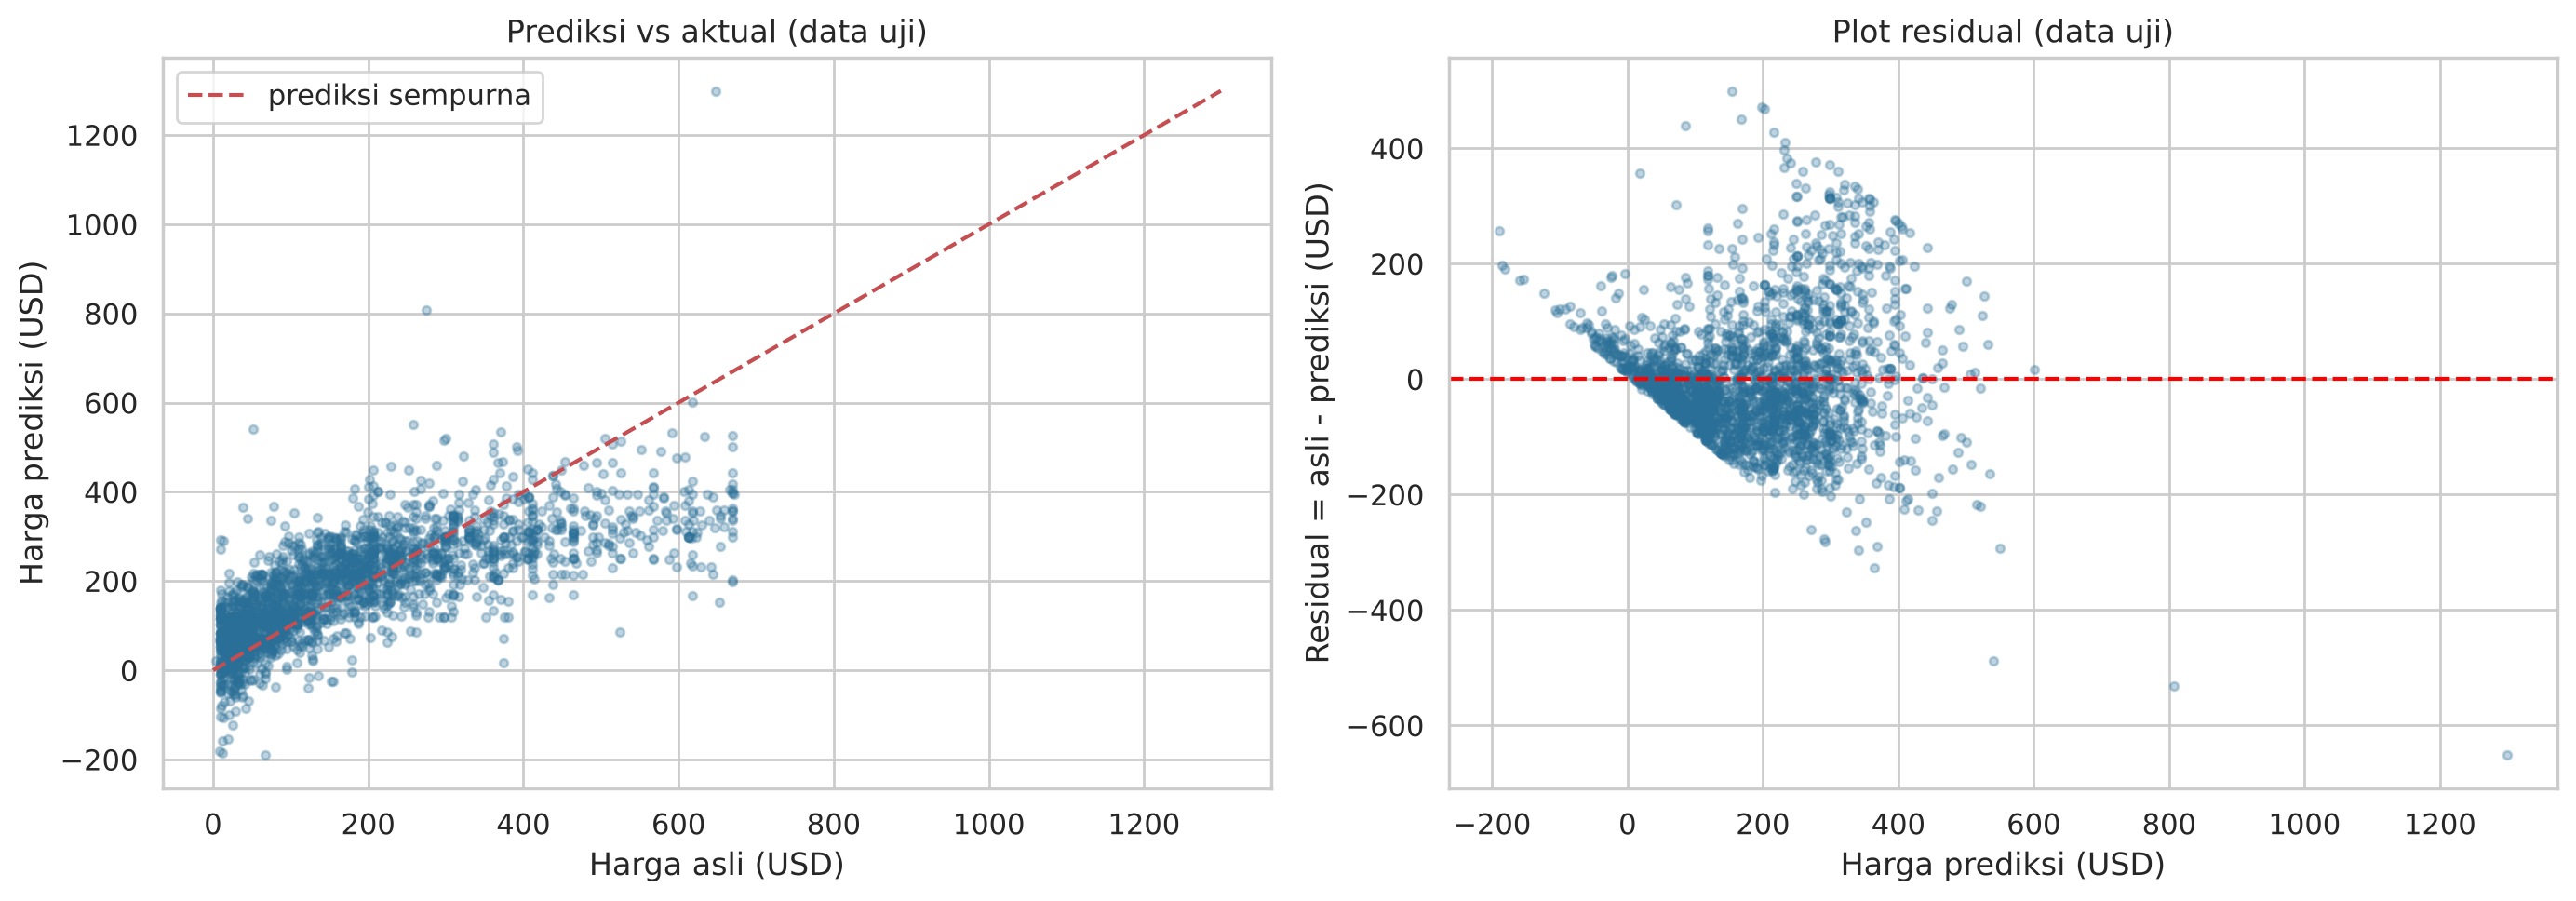

Prediksi negatif: 90 dari 2290


In [16]:
resid = y_asli - y_pred
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_asli, y_pred, alpha=0.3, s=10, color="#2a6f97")
lim = [0, max(y_asli.max(), y_pred.max())]
axes[0].plot(lim, lim, "r--", label="prediksi sempurna")
axes[0].set_xlabel("Harga asli (USD)"); axes[0].set_ylabel("Harga prediksi (USD)")
axes[0].set_title("Prediksi vs aktual (data uji)"); axes[0].legend()

axes[1].scatter(y_pred, resid, alpha=0.3, s=10, color="#2a6f97")
axes[1].axhline(0, color="red", ls="--")
axes[1].set_xlabel("Harga prediksi (USD)"); axes[1].set_ylabel("Residual = asli - prediksi (USD)")
axes[1].set_title("Plot residual (data uji)")
plt.tight_layout(); plt.savefig(f"{REPORTS}/grafik5_prediksi_residual.png", dpi=150); plt.show()
print("Prediksi negatif:", (y_pred < 0).sum(), "dari", len(y_pred))

**Koefisien model.**

In [17]:
# Regresi sederhana
ms = model_final[f"Sederhana ({fitur_sederhana})"]["model"]
print(f"Regresi sederhana: harga = {ms.intercept_:.2f} + {ms.coef_[0]:.2f} x {fitur_sederhana}\n")

# Regresi berganda
mb = model_final["Berganda"]
nama_fitur = mb["prep"].get_feature_names_out()
koef = pd.Series(mb["model"].coef_, index=nama_fitur).round(2)
print("Intersep regresi berganda:", round(mb["model"].intercept_, 2))
print("\nKoefisien fitur numerik:")
print(koef[koef.index.str.startswith("num__")])
print("\nKoefisien room_type:")
print(koef[koef.index.str.contains("room_type")])
print("\n5 kawasan dengan koefisien tertinggi dan terendah:")
kaw = koef[koef.index.str.contains("neighborhood")].sort_values()
print(pd.concat([kaw.head(5), kaw.tail(5)]))

Regresi sederhana: harga = 48.95 + 56.49 x bathrooms

Intersep regresi berganda: -287.55

Koefisien fitur numerik:
num__person_capacity    14.32
num__bedrooms            1.23
num__bathrooms          24.77
num__beds               -6.60
num__reviews_count      -0.89
num__star_rating        62.64
dtype: float64

Koefisien room_type:
cat__room_type_entire_home     60.65
cat__room_type_private_room    11.31
cat__room_type_shared_room    -71.97
dtype: float64

5 kawasan dengan koefisien tertinggi dan terendah:
cat__neighborhood_Lovina        -55.17
cat__neighborhood_Nusa Penida   -49.17
cat__neighborhood_Bedugul       -39.64
cat__neighborhood_Amed          -36.22
cat__neighborhood_Kintamani     -31.58
cat__neighborhood_Ubud           33.63
cat__neighborhood_Canggu         37.05
cat__neighborhood_Bali           57.83
cat__neighborhood_Nusa Dua       60.80
cat__neighborhood_Seminyak       68.59
dtype: float64


**Interpretasi hasil data uji.**

| Model | MAE uji (USD) | RMSE uji (USD) | R2 uji |
|---|---|---|---|
| Dummy | 126,64 | 157,81 | -0,001 |
| Regresi sederhana (`bathrooms`) | 91,36 | 130,32 | 0,317 |
| **Regresi berganda** | **79,55** | **107,56** | **0,535** |

- **MAE** regresi berganda 79,55 USD: rata-rata tebakan harga meleset sekitar **80 USD per malam**. Dibanding harga rata-rata data latih sekitar 189 USD, ini selisih yang masih cukup besar (sekitar 42%), sehingga model cocok sebagai **panduan harga awal**, bukan penentu harga presisi.
- **RMSE** (107,56) lebih besar dari MAE karena menghukum kesalahan besar lebih berat. Artinya ada sejumlah listing yang tebakannya meleset jauh.
- **R2 = 0,535**: model menjelaskan sekitar 53,5% variasi harga. Sisanya (sekitar 46%) dipengaruhi faktor yang tidak ada di data, misalnya kualitas fasilitas, foto, pemandangan, atau musim.
- **Cek overfitting:** R2 latih 0,523 dan R2 uji 0,535, MAE latih 79,78 dan MAE uji 79,55. Hampir sama, jadi **tidak ada overfitting**. Model justru cenderung belum cukup kompleks (*underfit* ringan), yang wajar untuk model linear.
- **Grafik prediksi vs aktual dan residual** menunjukkan pola *regresi ke tengah*: model cenderung **menebak terlalu tinggi untuk listing murah** (residual negatif) dan **terlalu rendah untuk listing mahal** (di atas sekitar 400 USD, prediksi umumnya hanya 300-400 USD). Titik-titik juga menyebar lebar pada prediksi 100-400 USD. Selain itu ada **90 dari 2.290 prediksi (sekitar 3,9%) bernilai negatif** untuk listing sangat murah, yang tidak masuk akal sebagai harga, dan 2 titik dengan prediksi ekstrem (di atas 800 USD) yang kemungkinan berasal dari nilai fitur yang sangat besar pada listing tersebut.

**Tafsir koefisien.**
- Regresi sederhana: harga = 48,95 + 56,49 x `bathrooms`. Setiap **tambahan 1 kamar mandi, harga sewa naik sekitar 56 USD per malam** (jika hanya melihat satu fitur ini).
- Regresi berganda (efek masing-masing fitur dengan fitur lain dianggap tetap): `bathrooms` +24,8 USD per kamar mandi, `person_capacity` +14,3 USD per tamu. Koefisien `bathrooms` mengecil dari 56 menjadi 25 karena efeknya kini dibagi dengan fitur lain yang berkorelasi kuat (kapasitas, kamar tidur, jenis kamar). Koefisien `bedrooms` (+1,2) dan `beds` (-6,6) tampak kecil bahkan negatif bukan berarti kamar tidur tidak berpengaruh, melainkan informasinya **sudah terwakili** `bathrooms` dan `person_capacity` (kolinearitas, korelasi `bedrooms` dengan `bathrooms` 0,89).
- `room_type`: `entire_home` (+60,7 USD) menaikkan harga dan `shared_room` (-72,0 USD) menurunkannya relatif terhadap jenis kamar lain, dengan fitur lain tetap. Ini searah dengan pola pada eksplorasi.
- `star_rating` (+62,6 per bintang) perlu dibaca hati-hati: lebih dari separuh nilainya hasil imputasi median, sehingga koefisien ini tidak boleh ditafsirkan sebagai efek rating yang pasti.
- Kawasan: Seminyak (+68,6), Nusa Dua (+60,8), dan Bali (+57,8) menaikkan harga, sedangkan Lovina (-55,2) dan Nusa Penida (-49,2) menurunkannya.

### Keputusan saya (Tahap 5)

- Data uji dipakai **satu kali** untuk menilai ketiga model.
- Regresi berganda tetap **model terbaik** pada data uji pada semua metrik (MAE, RMSE, R2).
- Model tidak overfit, tetapi kemampuan prediksinya terbatas (R2 0,535). Ini dilaporkan apa adanya.

# Tahap 6 - Kesimpulan

**Apakah model layak dibanding baseline? Ya.** Model terpilih adalah **regresi linear berganda**, dengan dua alasan berbasis angka:

1. **Jauh lebih akurat dari baseline.** MAE data uji turun dari 126,64 USD (DummyRegressor) menjadi 79,55 USD, penurunan sekitar 37%. R2 naik dari -0,001 menjadi 0,535.
2. **Lebih baik dari regresi sederhana dan stabil.** MAE 79,55 USD lawan 91,36 USD milik regresi sederhana (`bathrooms`). Skor CV (80,09 USD) hampir sama dengan skor uji (79,55 USD) dan R2 latih (0,523) mirip R2 uji (0,535), jadi hasilnya konsisten dan tidak overfit.

**Temuan utama.** Jenis kamar (`entire_home` mahal, `shared_room` murah), jumlah kamar mandi, kapasitas tamu, dan kawasan (Seminyak dan Nusa Dua mahal) adalah penentu harga yang paling jelas.

**Rekomendasi untuk pengguna.**
- *Host baru:* pakai prediksi model sebagai harga awal, lalu sesuaikan dengan kelebihan properti yang tidak tercatat di data (pemandangan, fasilitas, foto). Anggap margin kesalahan sekitar 80 USD.
- *Wisatawan:* listing yang harganya jauh di atas prediksi untuk spesifikasi yang sama layak dibandingkan dengan listing lain.

**Keterbatasan.**
- Data berasal dari **April 2018** dan hasil scraping yang bukan daftar lengkap, sehingga harga tidak mewakili kondisi sekarang.
- Model hanya berlaku untuk harga **sampai 672 USD per malam** (outlier dibuang). Villa mewah di luar cakupan.
- Model linear menghasilkan 90 prediksi negatif (sekitar 3,9% data uji), cenderung melebihkan harga listing murah dan meremehkan harga listing mahal.
- `star_rating` kosong sekitar 54% dan diisi median, sehingga pengaruh rating tidak bisa ditafsirkan dengan yakin.
- Fitur saling berkorelasi kuat sehingga koefisien individual sulit ditafsirkan.

**Saran perbaikan.**
- Memodelkan `log(harga)` untuk meredam kemiringan dan mencegah prediksi negatif.
- Menambah fitur fasilitas (kolam renang, AC, dan lain-lain) dan data harga yang lebih baru.
- Mencoba model non-linear seperti random forest sebagai pembanding (di luar cakupan UTS ini).